# Weather histories and findings at slaughter
One outcome per animal. Each finding uses all farms with an explicit indicator for it. Set the weather horizon, pointwise confidence level and minimum date count below, then run the notebook.

Weather candidates are pneumonia and pleurisy (respiratory findings), and lungworm and liver fluke (pasture parasites). Pleurisy is an indirect indicator and its onset date is unknown. [Respiratory disease study](https://pubmed.ncbi.nlm.nih.gov/22147486/) · [Cattle parasite guidance](https://ahdb.org.uk/knowledge-library/essential-health-checks-for-growing-and-finishing-dairy-cattle).

In [5]:
days_before = 120          # days preceding slaughter
confidence_level = 0.95   # two-sided pointwise interval
min_dates = 10             # required separately for dates with cases and dates without cases

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BSpline
from IPython.display import display

plt.rcParams.update({'font.family': 'serif', 'axes.spines.top': False, 'axes.spines.right': False})
a = pd.read_excel('data/beef_raw/beef_farms1_2.xlsx', sheet_name=1)
date = pd.to_datetime(a['Date processed (kill date)'])
flags = a.loc[:, 'Liver fluke':'Lung worm']
# Exclude non-diagnostic entries.
flags = flags.drop(columns=['Other', 'Bruised', 'Condemned Part', 'Inoculation'])
assert flags.isin([0, 1]).all().all()
b = pd.read_excel('data/beef_raw/beef_farm3.xlsx')
b['date'] = pd.to_datetime(b['Date processed (kill date)'], dayfirst=True).ffill()
eid = b.EID.astype('string').str.strip()
b = b.loc[~(eid.notna() & eid.duplicated())]
shared = {'arthritis':'Arthritis', 'cirrhosis defect':'Cirrhosis', 'pleuresy':'Pleurisy',
          'pyogenic lesions':'Pyogenic Lesions', 'peritonitis':'Peritonitis'}
assert b[list(shared)].isin([0, 1]).all().all()
animals = pd.concat([flags.assign(date=date, farm='First', animal=a['Animals category']),
                     b[list(shared)].rename(columns=shared).assign(date=b.date, farm='Second', animal=b.Type)],
                    ignore_index=True)
animals['animal'] = animals.animal.str.strip().str.lower()
prev = animals.groupby('date')[flags.columns].mean()
support = animals.groupby('farm')[flags.columns].count().T
support['Cases'] = animals[flags.columns].sum()
support['Dates with cases'] = prev.gt(0).sum()
support['Dates without cases'] = prev.eq(0).sum()
support['Weather candidate'] = support.index.isin(['Pneumonia', 'Pleurisy', 'Lung worm', 'Liver fluke'])
support['Screened'] = support['Weather candidate'] & support[['Dates with cases','Dates without cases']].min(axis=1).ge(min_dates)
display(support.rename(columns={'First':'First farm examined','Second':'Second farm examined'}))

farm,First farm examined,Second farm examined,Cases,Dates with cases,Dates without cases,Weather candidate,Screened
Liver fluke,522,0,4.0,3,32,True,False
Actino,522,0,28.0,15,20,False,False
Cirrhosis,522,351,23.0,13,37,False,False
Peritonitis,522,351,76.0,24,26,False,False
Pleurisy,522,351,75.0,26,24,True,True
Pyogenic Lesions,522,351,47.0,21,29,False,False
Melanosis,522,0,3.0,3,32,False,False
Xanthosis,522,0,1.0,1,34,False,False
Arthritis,522,351,2.0,2,48,False,False
Epicarditis Pericarditis,522,0,3.0,3,32,False,False


## Animal-level functional logistic regression
Each panel shows the association between daily weather and the log-odds of the finding, adjusted for farm, animal type and season. Dates are resampled within farm for the pointwise bootstrap intervals. Brown shading marks intervals excluding zero.

In [7]:
w = pd.read_csv('data/weather_preprocessed.csv')
w.index = pd.to_datetime(w['Date(NZST)']+' '+w['Time(NZST)']) - pd.Timedelta(nanoseconds=1)
fields = {'MnTemp(C)': 'Temperature', 'MnRH(%)': 'Humidity', 'MnSpd(mps)': 'Wind speed',
          'Rain(mm)': 'Rain', 'RadGlb(MJ/m2)': 'Radiation', 'THI': 'THI', 'HLI': 'HLI'}
obs = w[list(fields)].rename(columns=fields)
angle = np.deg2rad(w['MnDir(degT)'])
obs['Wind north component'], obs['Wind east component'] = np.cos(angle), np.sin(angle)
daily = obs.resample('D').mean().where(obs.resample('D').count() >= 130)
daily[['Rain','Radiation']] *= 144  # estimated daily totals from observed intervals

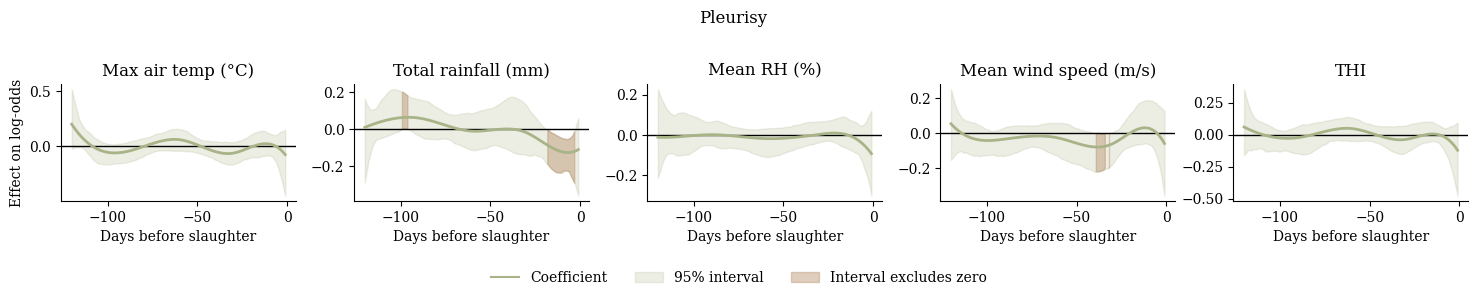

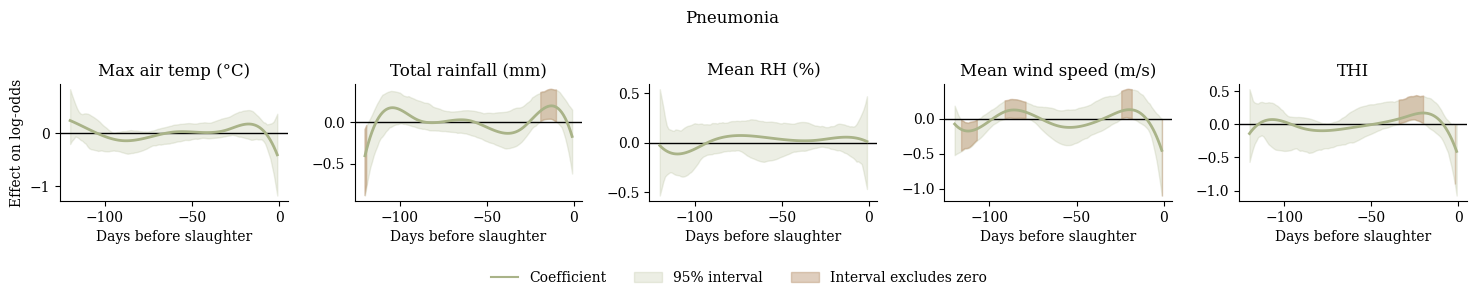

In [8]:
from sklearn.linear_model import LogisticRegression
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

lag = np.arange(-days_before, 0)
knots = np.r_[[lag[0]]*4, np.linspace(*lag[[0,-1]], 5)[1:-1], [lag[-1]]*4]
B = BSpline.design_matrix(lag, knots, 3).toarray()
maximum = w['MnTemp(C)'].resample('D').max().where(daily.Temperature.notna())
series = daily.assign(Maximum=maximum)[['Maximum','Rain','Humidity','Wind speed','THI']]
titles = ['Max air temp (°C)', 'Total rainfall (mm)', 'Mean RH (%)', 'Mean wind speed (m/s)', 'THI']
dates = prev.index
# Project standardized daily exposures onto a smooth lag basis. Each animal inherits its date's history.
design = {}
for field in series:
    s = (series[field] - series[field].mean()) / series[field].std()
    histories = np.array([s.reindex(d + pd.to_timedelta(lag, unit='D')).values for d in dates])
    h = pd.DataFrame(histories, index=dates).dropna(thresh=int(np.ceil(.9*days_before)))
    design[field] = pd.DataFrame(h.interpolate(axis=1, limit_direction='both').values @ B, index=h.index)

tail = (1 - confidence_level) / 2
green, brown = '#A9B388', '#B99470'
for disease in support.index[support.Screened]:
    fig, axes = plt.subplots(1, 5, figsize=(15, 2.9))
    for ax, (field, history), title in zip(axes, design.items(), titles):
        cohort = animals.dropna(subset=[disease]).loc[lambda x: x.date.isin(history.index)]
        y = cohort[disease].to_numpy()
        phase = 2*np.pi*cohort.date.dt.dayofyear/365.25
        X = np.column_stack([history.loc[cohort.date], pd.get_dummies(cohort[['animal','farm']], dtype=float),
                             np.sin(phase), np.cos(phase)])
        groups, unique = pd.factorize(cohort.date)
        farms = cohort.assign(group=groups).groupby('group').farm.first()
        assert cohort.groupby('date').farm.nunique().max() == 1
        blocks = [g.index.to_numpy() for _, g in farms.groupby(farms)]
        def fit(weights):
            model = LogisticRegression(solver='liblinear', C=1, max_iter=1000, intercept_scaling=10)
            model.fit(X, y, sample_weight=weights)
            return B @ model.coef_[0, :B.shape[1]]
        beta = fit(np.ones(len(y)))
        rng = np.random.default_rng(2210)
        samples = []
        for _ in range(499):
            draw = np.concatenate([rng.choice(g, len(g)) for g in blocks])
            weights = np.bincount(draw, minlength=len(unique))[groups]
            if np.unique(y[weights > 0]).size == 2:
                samples.append(fit(weights))
        lo, hi = np.quantile(samples, [tail, 1-tail], axis=0)
        ax.axhline(0, color='black', lw=1)
        ax.fill_between(lag, lo, hi, color=green, alpha=.22)
        ax.fill_between(lag, lo, hi, where=(lo>0)|(hi<0), color=brown, alpha=.45)
        ax.plot(lag, beta, color=green, lw=2)
        ax.set(title=title, xlabel='Days before slaughter')
    axes[0].set_ylabel('Effect on log-odds')
    fig.suptitle(disease)
    fig.legend([Line2D([], [], color=green), Patch(color=green, alpha=.22), Patch(color=brown, alpha=.45)],
               ['Coefficient', f'{confidence_level:.0%} interval', 'Interval excludes zero'], loc='lower center', ncol=3, frameon=False)
    fig.tight_layout(rect=[0,.12,1,.96])
    plt.show()